# Evaluación 1 grupal — Proyecto CRISP-DM

**Proyecto:** Sistema de recomendación de películas con **MovieLens 1M**
**Asignatura:** Minería de Datos · **Docente:** Enrique Alejandro Laurel Cossio · **Fecha:** Octubre 2026

Cada pregunta tiene su **respuesta** y, debajo, las celdas de **código que la demuestran**. Todos los números de las respuestas salen de esas celdas.

Todo el cuaderno usa un solo dataset: **MovieLens 1M** (1.000.209 calificaciones, 6.040 usuarios, 3.706 películas), ya limpio en [`WRANGLER/03_preparacion_datos/datos/`](WRANGLER/03_preparacion_datos/datos/). Se trabaja con dos modelos:

- **Recomendador** (regresión: predecir cuántas estrellas pondrá el usuario). Preguntas 1, 2, 7 y 9. Código de [`03a_baselines.py`](WRANGLER/04_modelado/scripts/03a_baselines.py), [`03b_mf_numpy.py`](WRANGLER/04_modelado/scripts/03b_mf_numpy.py) y [`03c_antes_despues.py`](WRANGLER/04_modelado/scripts/03c_antes_despues.py).
- **Árbol de decisión** (clasificación: ¿le gustará la película?). Preguntas 4 a 10. Código de [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb), que usa el mismo target, variables y partición que [`regresion_logistica.ipynb`](WRANGLER/07_regresion_logistica/regresion_logistica.ipynb).

**Para ejecutarlo:** elegir el kernel `.venv` (creado con [`requirements.txt`](requirements.txt)) y usar *Ejecutar todo*. Tarda alrededor de un minuto.

<a id="pregunta-0"></a>

## 0. Carga de datos

Se importan las librerías y se cargan los archivos de MovieLens 1M que deja la fase de preparación. Si falta alguno, la celda indica cuál.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
SEED = 42            # división del recomendador (la misma de 03a_baselines.py)
RANDOM_STATE = 777   # división del árbol (la misma de la regresión logística)


def metricas_clasificacion(y_real, prob, umbral=0.5):
    pred = (prob > umbral).astype(int)
    return {"accuracy": accuracy_score(y_real, pred),
            "balanced_accuracy": balanced_accuracy_score(y_real, pred),
            "precision": precision_score(y_real, pred, zero_division=0),
            "recall": recall_score(y_real, pred, zero_division=0),
            "f1": f1_score(y_real, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_real, prob),
            "average_precision": average_precision_score(y_real, prob)}

In [2]:
DATOS = Path("WRANGLER/03_preparacion_datos")
for ruta in (DATOS / "datos/datos_limpios.parquet", DATOS / "datos/usuarios.csv",
             DATOS / "datos/peliculas_limpias.csv", DATOS / "reporte_preparacion.json"):
    if not ruta.exists():
        raise FileNotFoundError(f"No se encontró {ruta}. Abre el cuaderno desde la raíz del repositorio.")

ml1m = pd.read_parquet(DATOS / "datos/datos_limpios.parquet")
usuarios = pd.read_csv(DATOS / "datos/usuarios.csv")
peliculas = pd.read_csv(DATOS / "datos/peliculas_limpias.csv")
reporte = json.loads((DATOS / "reporte_preparacion.json").read_text(encoding="utf-8"))
print(f"Calificaciones: {len(ml1m):,} | Usuarios: {len(usuarios):,} | Películas en el catálogo: {len(peliculas):,}")

Calificaciones: 1,000,209 | Usuarios: 6,040 | Películas en el catálogo: 3,883


---
<a id="pregunta-1"></a>

## 1. ¿Qué problema concreto aborda su proyecto?

**Respuesta:** Los usuarios conocen una parte mínima del catálogo y la actividad se concentra en pocas películas (MovieLens 1M):

- El usuario mediano solo vio 96 de 3.706 películas (2,6%). El 97,4% del catálogo le es desconocido.
- El 80% de las calificaciones cae sobre 1.182 películas (31,9% del catálogo). El 68,1% restante se reparte solo el 20% de la actividad (cola larga).

**Decisión a apoyar:** implementar un sistema de recomendación por filtrado colaborativo que personalice las sugerencias, en lugar de mostrar siempre las mismas películas populares.

**Criterios de éxito de negocio:**

- **CN-1:** que la predicción se desvíe menos de 0,70 estrellas de la nota real (MAE < 0,70).
- **CN-2:** mejorar en al menos un 10% el error del ranking por popularidad (RMSE 0,977).
- **CN-3:** que el Top-10 recomendado cubra más del 31,9% del catálogo.
- **CN-4:** dar recomendaciones a los 6.040 usuarios, incluidos los 1.743 (28,9%) que vieron menos de 50 películas.

El cumplimiento de cada criterio se mide en la [sección 9.3](#seccion-9-3).

<a id="seccion-1-1"></a>

### 1.1 El problema en números

Se calcula, a partir de [`datos_limpios.parquet`](WRANGLER/03_preparacion_datos/datos/datos_limpios.parquet), cuántas películas ve cada usuario y cuántas películas concentran el 80% de las calificaciones. Son las mismas cifras de [`3_1_objetivo_del_negocio.txt`](WRANGLER/01_comprension_negocio/3_1_objetivo_del_negocio.txt).

In [3]:
vistas_por_usuario = ml1m.groupby("userId").size()
votos_por_pelicula = ml1m.groupby("movieId").size().sort_values(ascending=False)
n_usuarios = ml1m["userId"].nunique()
n_peliculas = ml1m["movieId"].nunique()

acumulado = votos_por_pelicula.cumsum() / votos_por_pelicula.sum()
peliculas_80 = int((acumulado < 0.80).sum()) + 1
mediana_vistas = vistas_por_usuario.median()
usuarios_menos_50 = int((vistas_por_usuario < 50).sum())

problema = pd.DataFrame([
    ("Usuarios", f"{n_usuarios:,}"),
    ("Películas calificadas", f"{n_peliculas:,}"),
    ("Mediana de películas vistas por usuario", f"{mediana_vistas:.0f}"),
    ("Catálogo que conoce el usuario mediano", f"{mediana_vistas / n_peliculas:.1%}"),
    ("Catálogo desconocido para el usuario mediano", f"{1 - mediana_vistas / n_peliculas:.1%}"),
    ("Películas que concentran el 80% de la actividad", f"{peliculas_80:,} ({peliculas_80 / n_peliculas:.1%})"),
    ("Catálogo en la cola larga", f"{1 - peliculas_80 / n_peliculas:.1%}"),
    ("Usuarios con menos de 50 películas vistas", f"{usuarios_menos_50:,} ({usuarios_menos_50 / n_usuarios:.1%})"),
], columns=["indicador", "valor"])
display(problema)

,indicador,valor
0,Usuarios,"6,040"
1,Películas calificadas,"3,706"
2,Mediana de películas vistas por usuario,96
3,Catálogo que conoce el usuario mediano,2.6%
4,Catálogo desconocido para el usuario mediano,97.4%
5,Películas que concentran el 80% de la actividad,"1,182 (31.9%)"
6,Catálogo en la cola larga,68.1%
7,Usuarios con menos de 50 películas vistas,"1,743 (28.9%)"


---
<a id="pregunta-2"></a>

## 2. ¿Cuál es la métrica principal y cómo se calcula?

**Respuesta:** RMSE (raíz del error cuadrático medio), en estrellas.

**Fórmula:** RMSE = √( (1/|T|) × Σ (r(u,i) − r_pred(u,i))² )

- **T:** conjunto de prueba (200.042 calificaciones, el 20%).
- **r(u,i):** calificación real (de 1 a 5). **r_pred(u,i):** calificación que predice el modelo, recortada a [1, 5].
- **Unidad:** estrellas. Un RMSE de 0,85 significa que el modelo se equivoca en unas 0,85 estrellas.
- **Valor obtenido:** 0,846 con el modelo de factorización matricial, frente a 0,977 del ranking por popularidad (práctica actual). Es un 13,4% mejor.
- **Meta:** RMSE ≤ 0,90 → **se cumple**.
- **Tipo:** métrica de rendimiento del modelo. Se conecta con el negocio a través de CN-2.
- **Cómo mejorarla:** probar otros hiperparámetros (k, reg, lr) y validar con validación cruzada de 5 particiones.

<a id="seccion-2-1"></a>

### 2.1 Modelos de referencia (baselines)

Antes de entrenar el modelo se miden cuatro predictores simples, con la misma división 80/20. Sirven para saber si el modelo aporta algo. Código de [`03a_baselines.py`](WRANGLER/04_modelado/scripts/03a_baselines.py).

In [4]:
datos = ml1m[["userId", "movieId", "rating"]]
rng = np.random.default_rng(SEED)
idx = rng.permutation(len(datos))
corte = int(len(datos) * 0.8)
train = datos.iloc[idx[:corte]].reset_index(drop=True)
test = datos.iloc[idx[corte:]].reset_index(drop=True)
real = test["rating"].to_numpy(float)
print(f"Entrenamiento: {len(train):,} | Prueba: {len(test):,}")


def rmse_mae(pred, real):
    error = real - np.clip(pred, 1.0, 5.0)
    return float(np.sqrt((error ** 2).mean())), float(np.abs(error).mean())

Entrenamiento: 800,167 | Prueba: 200,042


In [5]:
LAMBDA = 2.0
mu = train["rating"].mean()
media_usuario = train.groupby("userId")["rating"].mean()
media_pelicula = train.groupby("movieId")["rating"].mean()

desvio = train["rating"] - mu
g = desvio.groupby(train["movieId"])
b_i = g.sum() / (LAMBDA + g.size())
desvio2 = desvio - train["movieId"].map(b_i)
g = desvio2.groupby(train["userId"])
b_u = g.sum() / (LAMBDA + g.size())

predicciones = {
    "Media global": np.full(len(test), mu),
    "Media por usuario": test["userId"].map(media_usuario).fillna(mu).to_numpy(float),
    "Media por película (popularidad)": test["movieId"].map(media_pelicula).fillna(mu).to_numpy(float),
    "Media + sesgos (mu + b_u + b_i)": (mu + test["userId"].map(b_u).fillna(0)
                                         + test["movieId"].map(b_i).fillna(0)).to_numpy(float),
}
escalera = pd.DataFrame([(nombre, *rmse_mae(p, real)) for nombre, p in predicciones.items()],
                        columns=["modelo", "RMSE", "MAE"])
display(escalera)

,modelo,RMSE,MAE
0,Media global,1.1167,0.9328
1,Media por usuario,1.0344,0.8273
2,Media por película (popularidad),0.9765,0.7800
3,Media + sesgos (mu + b_u + b_i),0.9051,0.7150


<a id="seccion-2-2"></a>

### 2.2 Entrenamiento del modelo (factorización matricial)

El modelo predice r(u,i) = μ + b_u + b_i + p_u · q_i. Para no mirar el test al entrenar:

1. Se aparta el 10% del entrenamiento como **validación** y se entrena con el 90% restante.
2. **Parada temprana:** se detiene cuando el error en validación deja de bajar durante 6 épocas. La mejor época es el mínimo de la validación.
3. Se reentrena desde cero con **todo el entrenamiento** durante esas épocas.
4. El test se mide **una sola vez**, al final.

Código de [`03b_mf_numpy.py`](WRANGLER/04_modelado/scripts/03b_mf_numpy.py), con los hiperparámetros de [`mf_numpy.json`](WRANGLER/04_modelado/resultados/mf_numpy.json) (64 factores, elegidos porque dan menor error en validación que 32).

In [6]:
K, LR, REG, EPOCAS, LOTE, PACIENCIA = 64, 0.010, 0.045, 45, 4096, 6

cod_u = datos["userId"].astype("category")
cod_i = datos["movieId"].astype("category")
U = cod_u.cat.codes.to_numpy(np.int32)
I = cod_i.cat.codes.to_numpy(np.int32)
R = datos["rating"].to_numpy(np.float32)
n_u, n_i = len(cod_u.cat.categories), len(cod_i.cat.categories)

tr_idx, te_idx = idx[:corte], idx[corte:]
corte_val = int(len(tr_idx) * 0.9)
aj_idx, va_idx = tr_idx[:corte_val], tr_idx[corte_val:]   # validación: el último 10% del train
U_tr, I_tr = U[tr_idx], I[tr_idx]
print(f"{n_u:,} usuarios x {n_i:,} películas, {K} factores latentes")
print(f"Ajuste: {len(aj_idx):,} | Validación: {len(va_idx):,} | Prueba: {len(te_idx):,}")


def iniciar():
    gen = np.random.default_rng(7)
    P = gen.normal(0, 0.05, (n_u, K)).astype(np.float32)
    Q = gen.normal(0, 0.05, (n_i, K)).astype(np.float32)
    return gen, P, Q, np.zeros(n_u, np.float32), np.zeros(n_i, np.float32)


def una_epoca(filas, mu, gen, P, Q, bu, bi):
    orden = filas.copy()
    gen.shuffle(orden)
    for s in range(0, len(orden), LOTE):
        b = orden[s:s + LOTE]
        u, i, r = U[b], I[b], R[b]
        pu, qi = P[u], Q[i]
        err = r - (mu + bu[u] + bi[i] + np.einsum("ij,ij->i", pu, qi))
        e = err[:, None]
        np.add.at(bu, u, LR * (err - REG * bu[u]))
        np.add.at(bi, i, LR * (err - REG * bi[i]))
        np.add.at(P, u, LR * (e * qi - REG * pu))
        np.add.at(Q, i, LR * (e * pu - REG * qi))


def predecir(filas, mu, P, Q, bu, bi):
    return mu + bu[U[filas]] + bi[I[filas]] + np.einsum("ij,ij->i", P[U[filas]], Q[I[filas]])

6,040 usuarios x 3,706 películas, 64 factores latentes
Ajuste: 720,150 | Validación: 80,017 | Prueba: 200,042


In [7]:
# 1) y 2) elegir la época con la validación (el test no se mira)
mu_aj = R[aj_idx].mean()
gen, P, Q, bu, bi = iniciar()
historial, mejor, sin_mejora = [], None, 0
for epoca in range(1, EPOCAS + 1):
    una_epoca(aj_idx, mu_aj, gen, P, Q, bu, bi)
    rmse_ep, mae_ep = rmse_mae(predecir(va_idx, mu_aj, P, Q, bu, bi), R[va_idx])
    historial.append((epoca, rmse_ep, mae_ep))
    if mejor is None or rmse_ep < mejor[1]:
        mejor, sin_mejora = (epoca, rmse_ep), 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            break
mejor_epoca = mejor[0]
print(f"Mejor época según la validación: {mejor_epoca} (RMSE validación {mejor[1]:.4f}, se detuvo en la época {len(historial)})")

# 3) y 4) reentrenar con todo el train y medir el test una sola vez
mu_mf = R[tr_idx].mean()
gen, P, Q, bu, bi = iniciar()
for _ in range(mejor_epoca):
    una_epoca(tr_idx, mu_mf, gen, P, Q, bu, bi)
rmse_mf, mae_mf = rmse_mae(predecir(te_idx, mu_mf, P, Q, bu, bi), R[te_idx])
print(f"Prueba: RMSE = {rmse_mf:.4f} | MAE = {mae_mf:.4f}")

Mejor época según la validación: 22 (RMSE validación 0.8549, se detuvo en la época 28)


Prueba: RMSE = 0.8460 | MAE = 0.6652


<a id="seccion-2-3"></a>

### 2.3 Resultado: el modelo frente a los baselines

Se compara el RMSE del modelo con los cuatro baselines y se calcula cuánto mejora frente a la popularidad, que es la práctica actual.

In [8]:
rmse_pop = escalera.loc[2, "RMSE"]
resultado = pd.concat([escalera, pd.DataFrame([{"modelo": "Factorización matricial", "RMSE": rmse_mf, "MAE": mae_mf}])],
                      ignore_index=True)
resultado["mejora vs popularidad (%)"] = (rmse_pop - resultado["RMSE"]) / rmse_pop * 100
display(resultado)
print(f"Meta RMSE <= 0.90: {'CUMPLE' if rmse_mf <= 0.90 else 'NO CUMPLE'} (RMSE = {rmse_mf:.4f})")

,modelo,RMSE,MAE,mejora vs popularidad (%)
0,Media global,1.1167,0.9328,-14.3583
1,Media por usuario,1.0344,0.8273,-5.9283
2,Media por película (popularidad),0.9765,0.7800,0.0000
3,Media + sesgos (mu + b_u + b_i),0.9051,0.7150,7.3088
4,Factorización matricial,0.8460,0.6652,13.3619


Meta RMSE <= 0.90: CUMPLE (RMSE = 0.8460)


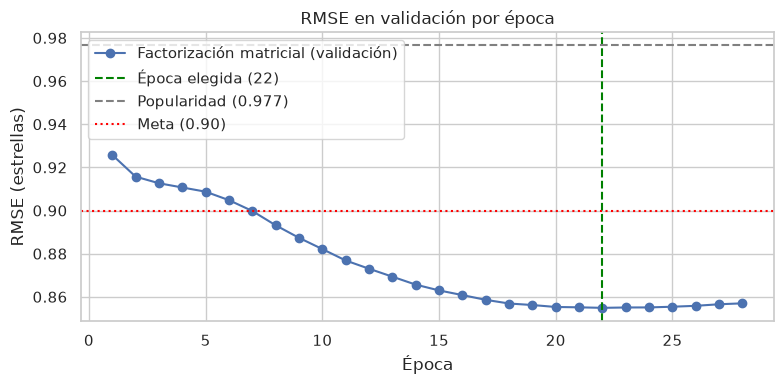

In [9]:
curva = pd.DataFrame(historial, columns=["época", "RMSE", "MAE"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva["época"], curva["RMSE"], marker="o", label="Factorización matricial (validación)")
ax.axvline(mejor_epoca, color="green", linestyle="--", label=f"Época elegida ({mejor_epoca})")
ax.axhline(rmse_pop, color="gray", linestyle="--", label=f"Popularidad ({rmse_pop:.3f})")
ax.axhline(0.90, color="red", linestyle=":", label="Meta (0.90)")
ax.set(title="RMSE en validación por época", xlabel="Época", ylabel="RMSE (estrellas)")
ax.legend()
fig.tight_layout()
plt.show()

---
<a id="pregunta-3"></a>

## 3. ¿Cuál es la unidad de análisis y cuántos registros/variables tiene?

**Respuesta:** La unidad de análisis es el par **(usuario, película)**: cada fila es la calificación que un usuario dio a una película. Los datos son MovieLens 1M (GroupLens; Harper & Konstan, 2015), con calificaciones de abril de 2000 a febrero de 2003.

| Archivo | Registros | Variables | Contenido |
|---|---:|---:|---|
| `datos_limpios.parquet` | 1.000.209 | 9 | userId, movieId, rating, timestamp, fecha, anio, title, genres, anio_estreno |
| `usuarios.csv` | 6.040 | 5 | userId, gender, age, occupation, zip |
| `peliculas_limpias.csv` | 3.883 | 4 | movieId, title, genres, anio_estreno |

- **Matriz usuario × película:** 6.040 × 3.706 = 22.384.240 celdas, de las que solo el 4,47% tiene dato (95,53% vacía).
- **Recomendador:** 800.167 calificaciones para entrenar y 200.042 para probar.
- **Árbol de decisión:** las mismas 1.000.209 calificaciones con 23 variables explicativas; 800.167 para entrenar y 200.042 para probar.

<a id="seccion-3-1"></a>

### 3.1 Dimensiones de los datos

Se muestran las filas y columnas de cada archivo y el tamaño de la matriz usuario × película.

In [10]:
dimensiones = pd.DataFrame([
    ("datos_limpios.parquet", *ml1m.shape, ", ".join(ml1m.columns)),
    ("usuarios.csv", *usuarios.shape, ", ".join(usuarios.columns)),
    ("peliculas_limpias.csv", *peliculas.shape, ", ".join(peliculas.columns)),
], columns=["archivo", "filas", "columnas", "variables"])
display(dimensiones)

celdas_matriz = n_usuarios * n_peliculas
print(f"Matriz: {n_usuarios:,} usuarios x {n_peliculas:,} películas = {celdas_matriz:,} celdas,"
      f" con dato {len(ml1m):,} ({len(ml1m) / celdas_matriz:.2%})")
print(f"Periodo de las calificaciones: {ml1m['fecha'].min():%Y-%m} a {ml1m['fecha'].max():%Y-%m}")

,archivo,filas,columnas,variables
0,datos_limpios.parquet,1000209,9,"userId, movieId, rating, timestamp, fecha, ani..."
1,usuarios.csv,6040,5,"userId, gender, age, occupation, zip"
2,peliculas_limpias.csv,3883,4,"movieId, title, genres, anio_estreno"


Matriz: 6,040 usuarios x 3,706 películas = 22,384,240 celdas, con dato 1,000,209 (4.47%)
Periodo de las calificaciones: 2000-04 a 2003-02


---
<a id="pregunta-4"></a>

## 4. ¿Qué problemas de calidad encontraron y qué preparación aplicaron?

**Respuesta:**

**Problemas de calidad (MovieLens 1M):**

- **Sin valores faltantes, sin calificaciones repetidas y sin ratings fuera de la escala** (1 a 5 estrellas enteras).
- **177 películas del catálogo no tienen ninguna calificación** (3.883 en el catálogo, 3.706 calificadas). No entran en la matriz.
- **Valores atípicos (método IQR):** 56.174 ratings de 1 estrella (todo lo que baja de 1,5), 475 usuarios con más de 454 calificaciones y 296 películas con más de 825 votos. **No se eliminaron** porque son valores válidos (alguien que odió una película, usuarios muy activos, películas muy populares), no errores.
- El problema real no es de calidad sino de **dispersión**: el 95,53% de la matriz usuario × película está vacía.

**Preparación aplicada** (fase 3, [`reporte_preparacion.json`](WRANGLER/03_preparacion_datos/reporte_preparacion.json)): carga de los tres archivos (separador `::`), control de nulos, duplicados, rango y calificaciones huérfanas, unión de calificaciones con películas, fecha y año de cada calificación, año de estreno sacado del título y matriz dispersa usuario × película. **No hubo que eliminar ninguna fila:** 1.000.209 al inicio y 1.000.209 al final.

**Preparación para el árbol de decisión** ([sección 4.3](#seccion-4-3)):

1. Variable objetivo `le_gusta`: 1 si el rating es ≥ 4, y 0 si no.
2. Variables del usuario y de la película: `gender_M`, `age`, `anio_estreno` y 18 dummies de género.
3. Variables de historial `tasa_usuario` y `tasa_pelicula`, calculadas **solo con los datos de entrenamiento** ([sección 7.1](#seccion-7-1)).

**Preparación del recomendador:** división 80/20 con semilla 42; medias, sesgos y factores calculados solo con los datos de entrenamiento.

<a id="seccion-4-1"></a>

### 4.1 Valores faltantes, duplicados y rango

Se cuentan los valores vacíos de cada archivo, las calificaciones repetidas, los ratings fuera de la escala y las películas sin votos.

In [11]:
faltantes = pd.DataFrame({"archivo": ["datos_limpios.parquet", "usuarios.csv", "peliculas_limpias.csv"],
                          "valores faltantes": [int(t.isna().sum().sum()) for t in (ml1m, usuarios, peliculas)]})
display(faltantes)

sin_votos = peliculas[~peliculas["movieId"].isin(ml1m["movieId"])]
limpieza = reporte["limpieza"]
print(f"Calificaciones repetidas (usuario, película): {ml1m.duplicated(['userId', 'movieId']).sum()}")
print(f"Ratings fuera de [1, 5]: {(~ml1m['rating'].between(1, 5)).sum()} | con media estrella: {(ml1m['rating'] % 1 != 0).sum()}")
print(f"Películas del catálogo sin calificaciones: {len(sin_votos)} de {len(peliculas):,}")
print(f"Limpieza: {limpieza['filas_inicio']:,} filas al inicio -> {limpieza['filas_fin']:,} al final"
      f" ({limpieza['total_eliminadas']} eliminadas)")

,archivo,valores faltantes
0,datos_limpios.parquet,0
1,usuarios.csv,0
2,peliculas_limpias.csv,0


Calificaciones repetidas (usuario, película): 0


Ratings fuera de [1, 5]: 0 | con media estrella: 0
Películas del catálogo sin calificaciones: 177 de 3,883
Limpieza: 1,000,209 filas al inicio -> 1,000,209 al final (0 eliminadas)


<a id="seccion-4-2"></a>

### 4.2 Valores atípicos (IQR)

Es atípico lo que queda fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR.

In [12]:
def atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((serie < inferior) | (serie > superior)).sum()), inferior, superior


atipicos = pd.DataFrame([
    ("Valor del rating", *atipicos_iqr(ml1m["rating"])),
    ("Calificaciones por usuario", *atipicos_iqr(vistas_por_usuario)),
    ("Calificaciones por película", *atipicos_iqr(votos_por_pelicula)),
], columns=["variable", "atípicos (IQR)", "límite inferior", "límite superior"])
display(atipicos)

,variable,atípicos (IQR),límite inferior,límite superior
0,Valor del rating,56174,1.5000,5.5000
1,Calificaciones por usuario,475,-202.0000,454.0000
2,Calificaciones por película,296,-442.5000,825.5000


<a id="seccion-4-3"></a>

### 4.3 Preparación de los datos para el árbol

Se une cada calificación con los datos del usuario y se crean el target y las variables. Es el mismo código de [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb).

In [13]:
df = ml1m.merge(usuarios, on="userId", how="left")
df["le_gusta"] = (df["rating"] >= 4).astype(int)
df["gender_M"] = (df["gender"] == "M").astype(int)
df["anio_estreno"] = df["anio_estreno"].astype("int64")
generos = df["genres"].str.get_dummies(sep="|")
generos.columns = ["genero_" + c.replace("'", "").replace("-", "_") for c in generos.columns]
df = pd.concat([df, generos.astype(int)], axis=1)

VARIABLES_BASE = ["gender_M", "age", "anio_estreno"] + list(generos.columns)
FEATURES = ["tasa_usuario", "tasa_pelicula"] + VARIABLES_BASE
print(f"Observaciones: {len(df):,} | variables explicativas: {len(FEATURES)}")
display(df[["userId", "movieId", "rating", "le_gusta", "gender_M", "age", "anio_estreno"]].head())

Observaciones: 1,000,209 | variables explicativas: 23


,userId,movieId,rating,le_gusta,gender_M,age,anio_estreno
0,1,1193,5.0000,1,0,1,1975
1,1,661,3.0000,0,0,1,1996
2,1,914,3.0000,0,0,1,1964
3,1,3408,4.0000,1,0,1,2000
4,1,2355,5.0000,1,0,1,1998


---
<a id="pregunta-5"></a>

## 5. ¿Qué resultado interesante encontraron en la exploración?

**Respuesta:** **Las películas más votadas son también las mejor valoradas.** El 10% de películas con más votos (730 o más) tiene una nota media de **3,79**, y el 25% con menos votos (33 o menos) solo **3,01**. La correlación de Spearman entre votos y nota media es **0,35**.

**Por qué importa:**

- Explica por qué el ranking por popularidad es difícil de superar (RMSE 0,977): popularidad y calidad van juntas.
- Las películas de la cola larga (el 68,1% del catálogo) tienen pocos votos y notas más bajas, así que el modelo tiende a recomendar las populares. Eso explica que el criterio de cobertura CN-3 no se cumpla ([sección 9.3](#seccion-9-3)).
- Con pocos votos la media no es confiable. Por eso las tasas del árbol se suavizan con 10 votos ficticios y el ranking por popularidad exige al menos 50 votos.
- **Cuidado:** la correlación no demuestra causalidad. Es probable que la gente vea más las películas que ya sabe que son buenas.

**Otros hallazgos:**

- **Las películas clásicas gustan más:** las de 1930 a 1950 reciben entre 72% y 75% de Me gusta; las de los 90, solo el 53%. De las películas antiguas solo se siguen viendo las que se recuerdan como buenas.
- **Los usuarios mayores dan más Me gusta:** 64,6% en el grupo de 56 años o más, frente a 54,9% en el de 18 a 24.
- **Los usuarios más activos califican más bajo** (Spearman −0,21 entre cantidad de calificaciones y nota media).
- El 57,5% de las calificaciones son de 4 o 5 estrellas y la media es 3,58.

<a id="seccion-5-1"></a>

### 5.1 Cálculo de los hallazgos

Se agrupan las películas según cuántos votos tienen y se compara su nota media. Después se calcula la tasa de Me gusta por década de estreno y por edad del usuario.

In [14]:
por_pelicula = ml1m.groupby("movieId")["rating"].agg(votos="size", nota_media="mean")
por_pelicula["grupo"] = pd.qcut(por_pelicula["votos"], [0, 0.25, 0.5, 0.75, 0.9, 1],
                                labels=["25% menos votadas", "25% a 50%", "50% a 75%", "75% a 90%", "10% más votadas"])
grupos = por_pelicula.groupby("grupo", observed=True).agg(películas=("votos", "size"), votos_mín=("votos", "min"),
                                                          votos_máx=("votos", "max"), nota_media=("nota_media", "mean"))
display(grupos)
print(f"Correlación votos vs nota media por película: Pearson {por_pelicula['votos'].corr(por_pelicula['nota_media']):.3f}"
      f" | Spearman {por_pelicula['votos'].corr(por_pelicula['nota_media'], method='spearman'):.3f}")

decada = (df["anio_estreno"] // 10 * 10).rename("década")
tasa_decada = df.groupby(decada)["le_gusta"].agg(["size", "mean"]).rename(columns={"size": "calificaciones", "mean": "% Me gusta"})
tasa_edad = df.groupby("age")["le_gusta"].mean()
por_usuario = ml1m.groupby("userId")["rating"].agg(["size", "mean"])
print(f"Me gusta por grupo de edad: {', '.join(f'{edad}: {tasa:.1%}' for edad, tasa in tasa_edad.items())}")
print(f"Correlación actividad del usuario vs su nota media (Spearman): {por_usuario['size'].corr(por_usuario['mean'], method='spearman'):.3f}")
print(f"Calificaciones >= 4: {df['le_gusta'].mean():.1%} | media: {ml1m['rating'].mean():.2f}")
display(tasa_decada.T)

,películas,votos_mín,votos_máx,nota_media
grupo,,,,
25% menos votadas,945,1,33,3.0069
25% a 50%,908,34,123,3.0940
50% a 75%,927,124,350,3.2479
75% a 90%,555,351,729,3.4909
10% más votadas,371,730,3428,3.7849


Correlación votos vs nota media por película: Pearson 0.358 | Spearman 0.346
Me gusta por grupo de edad: 1: 57.4%, 18: 54.9%, 25: 56.3%, 35: 58.6%, 45: 59.2%, 50: 62.2%, 56: 64.6%
Correlación actividad del usuario vs su nota media (Spearman): -0.209
Calificaciones >= 4: 57.5% | media: 3.58


década,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000
calificaciones,45.0000,1696.0000,12729.0000,21501.0000,35232.0000,48555.0000,82552.0000,224056.0000,532843.0000,41000.0000
% Me gusta,0.5333,0.7376,0.7418,0.7497,0.7205,0.7021,0.6645,0.5780,0.5322,0.5125


<a id="seccion-5-2"></a>

### 5.2 Gráficos

Nota media según la popularidad de la película, y tasa de Me gusta según la década de estreno.

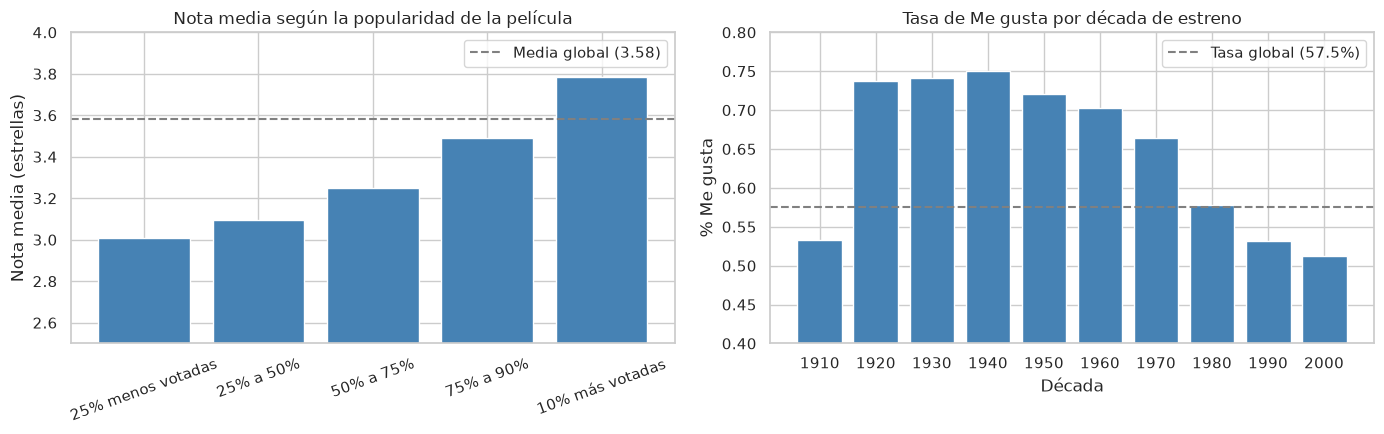

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(grupos.index.astype(str), grupos["nota_media"], color="steelblue")
axes[0].axhline(ml1m["rating"].mean(), color="gray", linestyle="--", label=f"Media global ({ml1m['rating'].mean():.2f})")
axes[0].set(title="Nota media según la popularidad de la película", ylabel="Nota media (estrellas)", ylim=(2.5, 4.0))
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend()

axes[1].bar(tasa_decada.index.astype(str), tasa_decada["% Me gusta"], color="steelblue")
axes[1].axhline(df["le_gusta"].mean(), color="gray", linestyle="--", label=f"Tasa global ({df['le_gusta'].mean():.1%})")
axes[1].set(title="Tasa de Me gusta por década de estreno", xlabel="Década", ylabel="% Me gusta", ylim=(0.4, 0.8))
axes[1].legend()
fig.tight_layout()
plt.show()

---
<a id="pregunta-6"></a>

## 6. ¿Cuál es la variable objetivo, qué clases tiene y qué modelo usaron?

**Respuesta:**

- **Variable objetivo:** `le_gusta` (binaria), creada a partir de `rating`.
- **Clases:** 0 = No me gusta (1, 2 o 3 estrellas): 424.928 casos (42,5%). 1 = Me gusta (4 o 5 estrellas): 575.281 casos (57,5%). Hay más Me gusta, pero no es un desbalance fuerte.
- **Modelo:** árbol de decisión (`DecisionTreeClassifier`), visto en clase. Como referencia se compara con una regresión logística con las mismas variables ([sección 9.1](#seccion-9-1)).
- **Por qué un árbol:** sus reglas se pueden leer, capta relaciones no lineales, no necesita normalizar las variables y muestra la importancia de cada una.
- **Configuración:** `max_depth=8` (elegida con una validación dentro de train, [sección 7.1](#seccion-7-1)), `min_samples_leaf=100` para que ninguna regla se base en pocos casos y `random_state=777`.

<a id="seccion-6-1"></a>

### 6.1 Clases y variables del modelo

Se cuentan los casos de cada clase y se listan las 23 variables explicativas.

In [16]:
clases = df["le_gusta"].value_counts().sort_index().to_frame("cantidad")
clases.index = ["0 = No me gusta (1-3 estrellas)", "1 = Me gusta (4-5 estrellas)"]
clases["%"] = clases["cantidad"] / clases["cantidad"].sum() * 100
display(clases)
print("Variables explicativas:", ", ".join(FEATURES))

,cantidad,%
0 = No me gusta (1-3 estrellas),424928,42.4839
1 = Me gusta (4-5 estrellas),575281,57.5161


Variables explicativas: tasa_usuario, tasa_pelicula, gender_M, age, anio_estreno, genero_Action, genero_Adventure, genero_Animation, genero_Childrens, genero_Comedy, genero_Crime, genero_Documentary, genero_Drama, genero_Fantasy, genero_Film_Noir, genero_Horror, genero_Musical, genero_Mystery, genero_Romance, genero_Sci_Fi, genero_Thriller, genero_War, genero_Western


---
<a id="pregunta-7"></a>

## 7. ¿Qué proporción usaron para entrenamiento/prueba y cómo separaron?

**Respuesta:** 80% para entrenamiento y 20% para prueba en los dos modelos.

- **Árbol de decisión:** `train_test_split(test_size=0.20, random_state=777, stratify=y)`, la misma división de la regresión logística. Quedan 800.167 casos para entrenar y 200.042 para probar, ambos con 57,52% de Me gusta.
- **Variables de historial:** `tasa_usuario` y `tasa_pelicula` se calculan **solo con train**. Dentro de train se usan 5 particiones: la tasa de cada fila sale de las otras 4, así ninguna fila ve su propia respuesta.
- **Profundidad del árbol:** se elige con un 20% de train separado como validación. El test no se usa hasta la evaluación final.
- **Recomendador:** permutación aleatoria con semilla 42. Quedan 800.167 para entrenar y 200.042 para probar, sin filas compartidas. La época de parada se elige con un 10% del entrenamiento separado como validación ([sección 2.2](#seccion-2-2)).

**Fuga de información ([sección 7.3](#seccion-7-3)):**

- Si las tasas se calcularan con **todos los datos** (incluido test), el AUC en prueba subiría de 0,782 a 0,789 y la exactitud de 72,0% a 72,6%. Sería un resultado falso: el modelo estaría viendo la respuesta.
- Si en train solo se **resta la propia calificación** (como en la regresión logística), el árbol aprende una pista falsa y el AUC baja a 0,770.
- **Recomendador (corregido):** antes, la parada temprana de [`03b_mf_numpy.py`](WRANGLER/04_modelado/scripts/03b_mf_numpy.py) elegía la mejor época mirando el RMSE de prueba, lo que daba un resultado algo optimista. Ahora la elige con la validación y el test se mide una sola vez.

<a id="seccion-7-1"></a>

### 7.1 División y entrenamiento del árbol

Se separa el 20% para prueba conservando la proporción de clases, se calculan las tasas de historial solo con train y se elige la profundidad con una validación.

In [17]:
X = df[["userId", "movieId"] + VARIABLES_BASE]
y = df["le_gusta"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
claves_train, claves_test = X_train[["userId", "movieId"]], X_test[["userId", "movieId"]]
X_train, X_test = X_train.copy(), X_test.copy()
print(f"Entrenamiento: {len(X_train):,} ({len(X_train) / len(X):.0%}) | Prueba: {len(X_test):,} ({len(X_test) / len(X):.0%})")
print(f"% Me gusta -> entrenamiento: {y_train.mean():.2%} | prueba: {y_test.mean():.2%}")

K_SUAVIZADO, N_PARTICIONES = 10, 5
tasa_global = y_train.mean()
entrenamiento = claves_train.assign(le_gusta=y_train)


def contar(datos, clave):
    return datos.groupby(clave)["le_gusta"].agg(n="count", s="sum")


def tasa_suavizada(claves, conteo, propia=None):
    n = claves.map(conteo["n"]).fillna(0)
    s = claves.map(conteo["s"]).fillna(0)
    if propia is not None:   # quita la propia calificación de la fila
        n, s = n - 1, s - propia
    return (s + K_SUAVIZADO * tasa_global) / (n + K_SUAVIZADO)


particion = np.zeros(len(X_train), dtype=int)
for numero, (_, filas) in enumerate(KFold(N_PARTICIONES, shuffle=True, random_state=RANDOM_STATE).split(X_train)):
    particion[filas] = numero

for clave, nombre in [("userId", "tasa_usuario"), ("movieId", "tasa_pelicula")]:
    valores = np.zeros(len(X_train))
    for numero in range(N_PARTICIONES):
        en_particion = particion == numero
        valores[en_particion] = tasa_suavizada(X_train.loc[en_particion, clave],
                                               contar(entrenamiento[~en_particion], clave)).to_numpy()
    X_train[nombre] = valores
    X_test[nombre] = tasa_suavizada(X_test[clave], contar(entrenamiento, clave))

X_train, X_test = X_train[FEATURES], X_test[FEATURES]

Entrenamiento: 800,167 (80%) | Prueba: 200,042 (20%)
% Me gusta -> entrenamiento: 57.52% | prueba: 57.52%


In [18]:
PROFUNDIDADES, MIN_MUESTRAS_HOJA = [2, 3, 4, 5, 6, 8, 10, 12, 15], 100
X_ajuste, X_valid, y_ajuste, y_valid = train_test_split(X_train, y_train, test_size=0.2,
                                                        random_state=RANDOM_STATE, stratify=y_train)
auc_validacion = {}
for profundidad in PROFUNDIDADES:
    prueba = DecisionTreeClassifier(max_depth=profundidad, min_samples_leaf=MIN_MUESTRAS_HOJA,
                                    random_state=RANDOM_STATE).fit(X_ajuste, y_ajuste)
    auc_validacion[profundidad] = roc_auc_score(y_valid, prueba.predict_proba(X_valid)[:, 1])
mejor_profundidad = max(auc_validacion, key=auc_validacion.get)
display(pd.Series(auc_validacion, name="AUC validación").rename_axis("max_depth").to_frame().T)

arbol = DecisionTreeClassifier(max_depth=mejor_profundidad, min_samples_leaf=MIN_MUESTRAS_HOJA,
                               random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Profundidad elegida: {mejor_profundidad} -> árbol final con {arbol.get_n_leaves()} hojas")

max_depth,2,3,4,5,6,8,10,12,15
AUC validación,0.7261,0.7541,0.7677,0.7749,0.7782,0.7800,0.7792,0.7770,0.7735


Profundidad elegida: 8 -> árbol final con 255 hojas


<a id="seccion-7-2"></a>

### 7.2 División del recomendador

Se comprueba que la división de la [sección 2.1](#seccion-2-1) no comparte ninguna calificación entre entrenamiento y prueba.

In [19]:
print(f"Entrenamiento: {len(tr_idx):,} | Prueba: {len(te_idx):,}")
print(f"Calificaciones compartidas: {len(np.intersect1d(tr_idx, te_idx))}")

Entrenamiento: 800,167 | Prueba: 200,042


Calificaciones compartidas: 0


<a id="seccion-7-3"></a>

### 7.3 Efecto de la fuga de información

Se entrena el mismo árbol con las tasas de historial calculadas de tres formas y se comparan las métricas en prueba:

1. **Con todos los datos** (incluido el test): hay fuga, el modelo ve la respuesta.
2. **Restando la propia fila** dentro de train: no hay fuga, pero deja una pista falsa que el árbol aprende.
3. **Con 5 particiones** de train: la forma usada en este cuaderno.

In [20]:
todos = pd.concat([entrenamiento, claves_test.assign(le_gusta=y_test)])
X_fuga_train, X_fuga_test, X_propia_train = X_train.copy(), X_test.copy(), X_train.copy()
for clave, nombre in [("userId", "tasa_usuario"), ("movieId", "tasa_pelicula")]:
    X_fuga_train[nombre] = tasa_suavizada(claves_train[clave], contar(todos, clave))
    X_fuga_test[nombre] = tasa_suavizada(claves_test[clave], contar(todos, clave))
    X_propia_train[nombre] = tasa_suavizada(claves_train[clave], contar(entrenamiento, clave), propia=y_train)


def probar_variante(X_entrenar, X_probar):
    modelo = DecisionTreeClassifier(**arbol.get_params()).fit(X_entrenar, y_train)
    return metricas_clasificacion(y_test, modelo.predict_proba(X_probar)[:, 1])


fuga = pd.DataFrame({
    "1. Con todos los datos (fuga)": probar_variante(X_fuga_train, X_fuga_test),
    "2. Restando la propia fila": probar_variante(X_propia_train, X_test),
    "3. Con 5 particiones (usado)": metricas_clasificacion(y_test, arbol.predict_proba(X_test)[:, 1]),
}).loc[["accuracy", "recall", "roc_auc"]]
display(fuga)

,1. Con todos los datos (fuga),2. Restando la propia fila,3. Con 5 particiones (usado)
accuracy,0.7255,0.7133,0.7200
recall,0.8283,0.8142,0.8189
roc_auc,0.7893,0.7695,0.7815


---
<a id="pregunta-8"></a>

## 8. ¿Cuáles son las variables más importantes y cómo lo determinaron?

**Respuesta:**

- **Método:** importancia de variables (`feature_importances_`) del árbol: cuánto ayuda cada variable a separar las clases en las divisiones del árbol (las importancias suman 1).
- **Resultado:** `tasa_pelicula` 0,660 y `tasa_usuario` 0,334; entre las dos suman el 99,4%. Les siguen `age` (0,0033) y `anio_estreno` (0,0015). Los 18 géneros y el sexo casi no se usan.
- **Interpretación:** el árbol decide por dos preguntas: ¿qué tan bien valorada está la película por los demás? y ¿qué tan generoso es este usuario? Es la idea del **filtrado colaborativo**: el historial vale más que los datos demográficos.
- **Coincide con la regresión logística:** también ahí `tasa_pelicula` y `tasa_usuario` son, por lejos, los coeficientes más fuertes.
- **Cuidado:** la importancia muestra qué usa el modelo para decidir, no qué causa un Me gusta. Que el género no aparezca no significa que no influya: su efecto ya está dentro de la tasa de la película.

<a id="seccion-8-1"></a>

### 8.1 Importancia de variables

Se ordena la importancia que el árbol entrenado asigna a cada variable.

,importancia
tasa_pelicula,0.6602
tasa_usuario,0.3341
age,0.0033
anio_estreno,0.0015
gender_M,0.0006
genero_Musical,0.0001
genero_Sci_Fi,0.0001
genero_Mystery,0.0000


tasa_pelicula + tasa_usuario: 99.4%


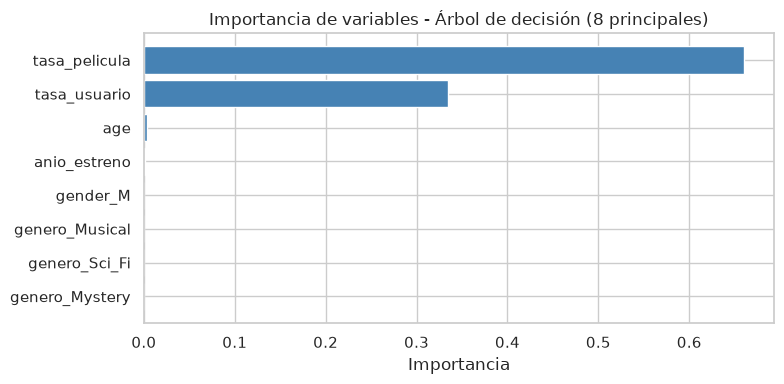

In [21]:
importancia = pd.Series(arbol.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(importancia.head(8).to_frame("importancia"))
print(f"tasa_pelicula + tasa_usuario: {importancia[['tasa_pelicula', 'tasa_usuario']].sum():.1%}")

principales = importancia.head(8).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(principales.index, principales.values, color="steelblue")
ax.set(title="Importancia de variables - Árbol de decisión (8 principales)", xlabel="Importancia")
fig.tight_layout()
plt.show()

---
<a id="pregunta-9"></a>

## 9. ¿Qué desempeño obtuvo el modelo y qué error reducir?

**Respuesta (árbol de decisión, 200.042 casos de prueba):**

| Métrica | Árbol de decisión | Línea base (clase mayoritaria) | Regresión logística |
|---|---:|---:|---:|
| Accuracy | 0,7200 | 0,5752 | 0,7199 |
| Balanced accuracy | 0,7025 | 0,5000 | 0,7043 |
| Precision | 0,7282 | 0,5752 | 0,7325 |
| Recall | 0,8189 | 1,0000 | 0,8083 |
| F1 | 0,7709 | 0,7303 | 0,7685 |
| ROC-AUC | 0,7815 | 0,5000 | 0,7815 |

- **Matriz de confusión:** 49.818 verdaderos negativos, 35.168 falsos positivos, 20.841 falsos negativos y 94.215 verdaderos positivos.
- **Error más importante a reducir:** los **falsos positivos (35.168)**, es decir, predecir que la película gustará cuando el usuario le pone 3 estrellas o menos. Un recomendador muestra solo 10 películas: cada falso positivo ocupa un lugar con una película que no gusta y hace perder confianza. Un falso negativo (20.841) cuesta menos, porque quedan muchas otras películas buenas para recomendar. Además es el error más frecuente. Para reducirlo se puede subir el umbral de 0,5.
- **Comparación:** el árbol supera a la línea base por 14,5 puntos de accuracy y en ROC-AUC (0,78 frente a 0,50). Con la regresión logística queda empatado, lo que indica que el límite está en las variables, no en el algoritmo.

**Respuesta (recomendador):** RMSE 0,846 y MAE 0,665 en prueba ([sección 2.3](#seccion-2-3)).

- **CN-1** (MAE < 0,70): **cumple**, 0,665.
- **CN-2** (mejora ≥ 10% frente a popularidad): **cumple**, 13,4%.
- **CN-3** (Top-10 cubre > 31,9% del catálogo): **no cumple**, 19,0% (703 de 3.706 películas). Queda como trabajo pendiente (ver el hallazgo de la pregunta 5).
- **CN-4** (recomendaciones para los 6.040 usuarios): **cumple**.
- **Precision@10:** de cada 10 películas recomendadas, el 80,7% tenía 4 estrellas o más, frente al 77,2% con popularidad (4.368 usuarios).

<a id="seccion-9-1"></a>

### 9.1 Métricas del árbol frente a otros modelos

Se compara el árbol con una línea base que siempre predice la clase más frecuente (Me gusta) y con una regresión logística (`sm.Logit`, como en [`regresion_logistica.ipynb`](WRANGLER/07_regresion_logistica/regresion_logistica.ipynb)) entrenada con las mismas variables y la misma división.

In [22]:
linea_base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
reg_logistica = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)
comparacion = pd.DataFrame({
    "Árbol de decisión": metricas_clasificacion(y_test, arbol.predict_proba(X_test)[:, 1]),
    "Línea base": metricas_clasificacion(y_test, linea_base.predict_proba(X_test)[:, 1]),
    "Regresión logística": metricas_clasificacion(y_test, reg_logistica.predict(sm.add_constant(X_test))),
})
display(comparacion)

,Árbol de decisión,Línea base,Regresión logística
accuracy,0.7200,0.5752,0.7199
balanced_accuracy,0.7025,0.5000,0.7043
precision,0.7282,0.5752,0.7325
recall,0.8189,1.0000,0.8083
f1,0.7709,0.7303,0.7685
roc_auc,0.7815,0.5000,0.7815
average_precision,0.8118,0.5752,0.8135


<a id="seccion-9-2"></a>

### 9.2 Matriz de confusión

Muestra los aciertos y errores del árbol en el conjunto de prueba.

VN = 49,818 | FP = 35,168 | FN = 20,841 | VP = 94,215


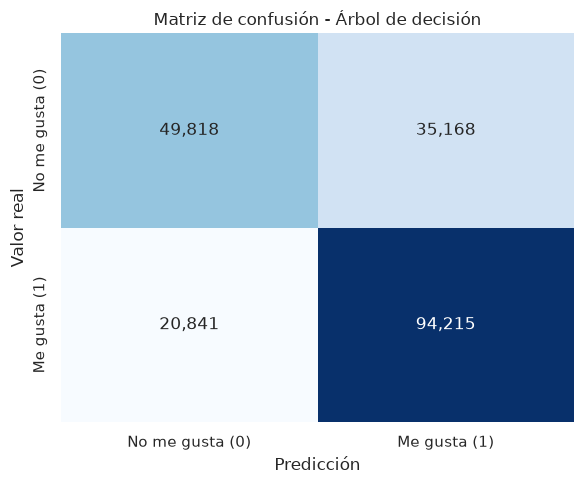

In [23]:
cm = confusion_matrix(y_test, arbol.predict(X_test))
(vn, fp), (fn, vp) = cm
print(f"VN = {vn:,} | FP = {fp:,} | FN = {fn:,} | VP = {vp:,}")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["No me gusta (0)", "Me gusta (1)"], yticklabels=["No me gusta (0)", "Me gusta (1)"], ax=ax)
ax.set(xlabel="Predicción", ylabel="Valor real", title="Matriz de confusión - Árbol de decisión")
fig.tight_layout()
plt.show()

<a id="seccion-9-3"></a>

### 9.3 Criterios de negocio del recomendador

Con el modelo de la [sección 2.2](#seccion-2-2) se arma el Top-10 de cada usuario, con películas que no vio, y se revisa cada criterio de la pregunta 1.

In [24]:
puntajes = mu_mf + bu[:, None] + bi[None, :] + P @ Q.T
puntajes[U_tr, I_tr] = -np.inf
top10 = np.argpartition(-puntajes, 10, axis=1)[:, :10]
cobertura = len(np.unique(top10)) / n_i
usuarios_con_top10 = int(np.isfinite(np.take_along_axis(puntajes, top10, axis=1)).all(axis=1).sum())
mejora_pop = (rmse_pop - rmse_mf) / rmse_pop

criterios = pd.DataFrame([
    ("CN-1", "MAE < 0.70", f"{mae_mf:.4f}", mae_mf < 0.70),
    ("CN-2", "mejora RMSE >= 10% vs popularidad", f"{mejora_pop:.1%}", mejora_pop >= 0.10),
    ("CN-3", "Top-10 cubre > 31.9% del catálogo", f"{cobertura:.1%} ({len(np.unique(top10)):,} de {n_i:,})", cobertura > 0.319),
    ("CN-4", "Top-10 para los 6,040 usuarios", f"{usuarios_con_top10:,} de {n_u:,}", usuarios_con_top10 == n_u),
], columns=["criterio", "meta", "resultado", "cumple"])
display(criterios)

,criterio,meta,resultado,cumple
0,CN-1,MAE < 0.70,0.6652,True
1,CN-2,mejora RMSE >= 10% vs popularidad,13.4%,True
2,CN-3,Top-10 cubre > 31.9% del catálogo,"19.0% (703 de 3,706)",False
3,CN-4,"Top-10 para los 6,040 usuarios","6,040 de 6,040",True


<a id="seccion-9-4"></a>

### 9.4 Precision@10 frente a popularidad

Para cada usuario con al menos 10 calificaciones de prueba se toman las 10 que el modelo puntúa más alto y se mide cuántas tenían 4 estrellas o más. Lo mismo con el ranking por popularidad. Código de [`03c_antes_despues.py`](WRANGLER/04_modelado/scripts/03c_antes_despues.py).

In [25]:
usuarios_mf = cod_u.cat.categories
peliculas_mf = cod_i.cat.categories
votos_train = train.groupby("movieId").size()
popularidad = media_pelicula.where(votos_train >= 50)
n_prueba = test.groupby("userId").size()

precision_10 = []
for usuario, grupo in test[test["userId"].isin(n_prueba[n_prueba >= 10].index)].groupby("userId"):
    u_cod = usuarios_mf.get_loc(usuario)
    i_cod = peliculas_mf.get_indexer(grupo["movieId"])
    pred_modelo = np.clip(mu_mf + bu[u_cod] + bi[i_cod] + Q[i_cod] @ P[u_cod], 1, 5)
    pred_popular = np.nan_to_num(grupo["movieId"].map(popularidad).to_numpy(float))
    reales = grupo["rating"].to_numpy()
    precision_10.append(((reales[np.argsort(-pred_modelo)[:10]] >= 4).mean(),
                         (reales[np.argsort(-pred_popular)[:10]] >= 4).mean()))
precision_10 = np.array(precision_10)
print(f"Usuarios evaluados: {len(precision_10):,}")
print(f"Precision@10 -> modelo: {precision_10[:, 0].mean():.1%} | popularidad: {precision_10[:, 1].mean():.1%}")

Usuarios evaluados: 4,368
Precision@10 -> modelo: 80.7% | popularidad: 77.2%


---
<a id="pregunta-10"></a>

## 10. ¿Qué visualización permite entender cómo toma decisiones el modelo?

**Respuesta:** El gráfico del árbol ([sección 10.1](#seccion-10-1)) y la tabla de sus ramas ([sección 10.2](#seccion-10-2)). Leídos juntos muestran cómo decide:

- **Primera pregunta:** ¿la película tiene una tasa de Me gusta mayor a 0,539? En entrenamiento, el 57,5% de las calificaciones son Me gusta.
- **Película bien valorada (> 0,539):** el 71% son Me gusta. Si además el usuario es generoso (`tasa_usuario` > 0,524) sube al 78%, y si la película supera 0,707 llega al 84%. El árbol predice "Me gusta".
- **Película mal valorada (≤ 0,539):** solo el 36% son Me gusta. Si además el usuario es exigente (`tasa_usuario` ≤ 0,581) baja al 25%, y si la película no pasa de 0,384 baja al 15%. El árbol predice "No me gusta".
- **Casos mezclados** (película mal valorada con usuario generoso, o al revés): quedan entre 51% y 56%. Ahí es donde el árbol más se equivoca.
- Todas las divisiones de los primeros niveles usan `tasa_pelicula` o `tasa_usuario`, lo que coincide con su importancia del 99,4% (pregunta 8).

**Aporte:** permite explicar a personas no técnicas por qué se recomienda una película ("está bien valorada y a ti te suelen gustar las películas"), y comprobar que el modelo usa variables razonables y no ruido.

<a id="seccion-10-1"></a>

### 10.1 Gráfico del árbol (primeros tres niveles)

Se muestran los primeros niveles para que el gráfico sea legible. Cada caja indica la regla, el porcentaje de casos de entrenamiento que llegan (`samples`) y la proporción de No me gusta / Me gusta (`value`).

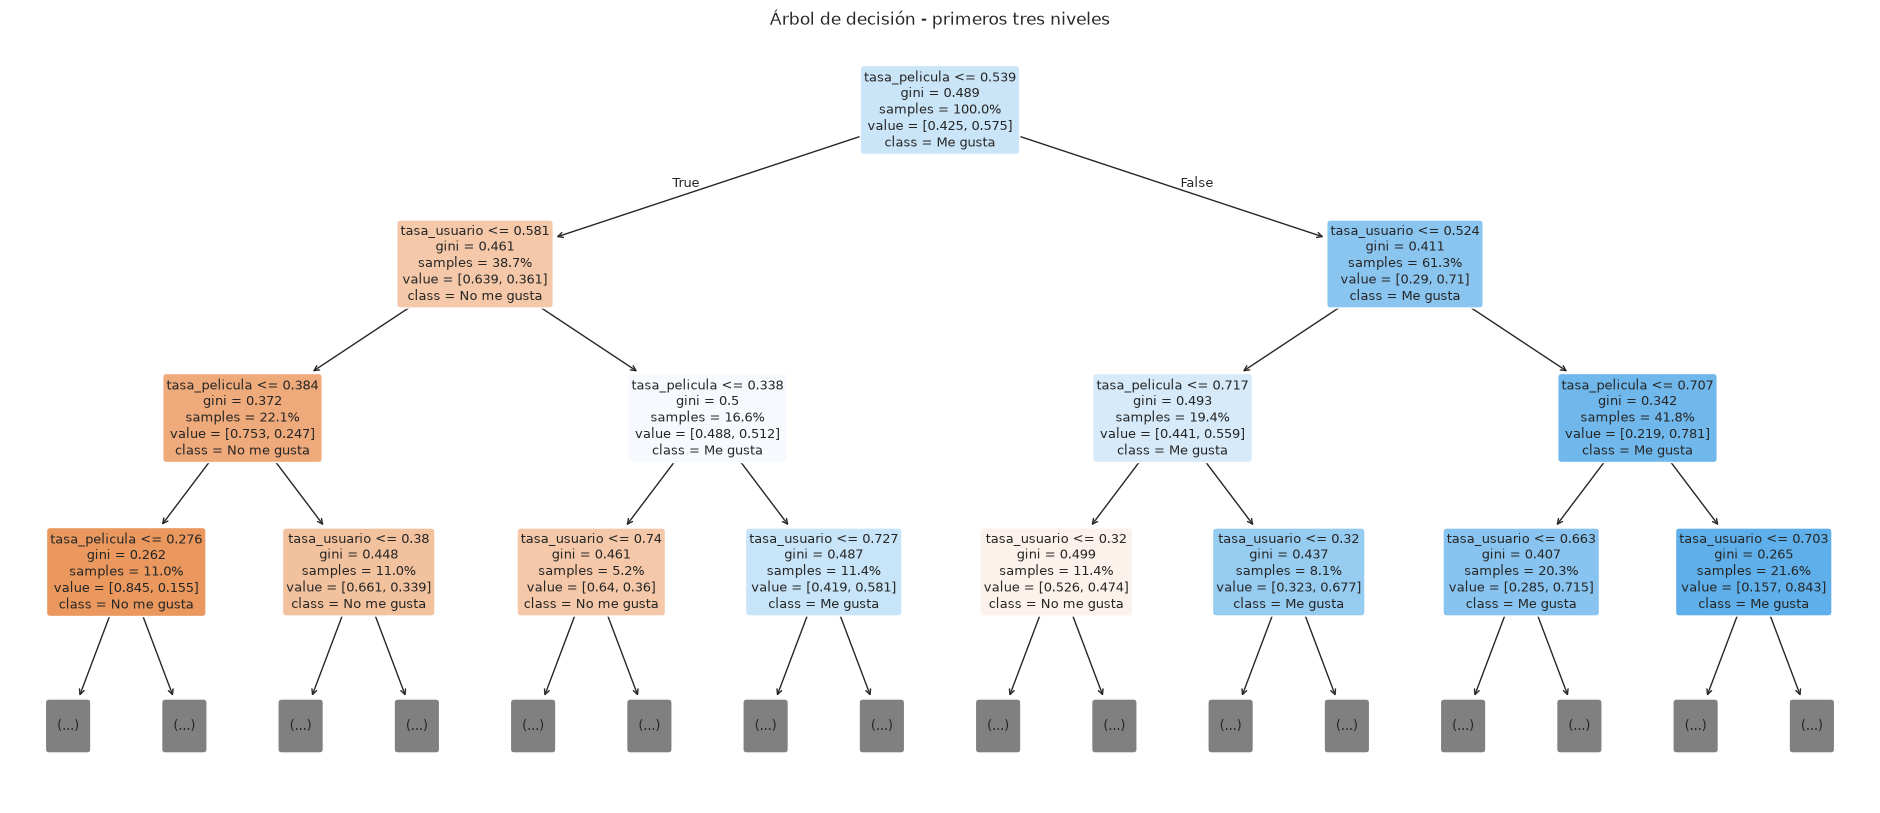

In [26]:
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(arbol, feature_names=FEATURES, class_names=["No me gusta", "Me gusta"], filled=True,
          rounded=True, proportion=True, max_depth=3, fontsize=9, ax=ax)
ax.set_title("Árbol de decisión - primeros tres niveles")
plt.show()

<a id="seccion-10-2"></a>

### 10.2 Reglas y porcentaje real de Me gusta por rama

Las reglas en texto muestran las condiciones del árbol; la tabla indica cuántos casos de entrenamiento llegan a cada rama de los dos primeros niveles y qué porcentaje de ellos es Me gusta.

In [27]:
print(export_text(arbol, feature_names=FEATURES, max_depth=2, decimals=3))

camino = arbol.decision_path(X_train)
t = arbol.tree_
filas = []


def recorrer(nodo, regla, nivel):
    llega = camino[:, nodo].toarray().ravel().astype(bool)
    filas.append((regla or "raíz", int(llega.sum()), y_train.to_numpy()[llega].mean() * 100))
    if nivel < 2 and t.children_left[nodo] != -1:
        variable, corte = FEATURES[t.feature[nodo]], t.threshold[nodo]
        prefijo = f"{regla} y " if regla else ""
        recorrer(t.children_left[nodo], f"{prefijo}{variable} <= {corte:.3f}", nivel + 1)
        recorrer(t.children_right[nodo], f"{prefijo}{variable} > {corte:.3f}", nivel + 1)


recorrer(0, "", 0)
display(pd.DataFrame(filas, columns=["rama", "casos de entrenamiento", "% Me gusta"]))

|--- tasa_pelicula <= 0.539
|   |--- tasa_usuario <= 0.581
|   |   |--- tasa_pelicula <= 0.384
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.384
|   |   |   |--- truncated branch of depth 6
|   |--- tasa_usuario >  0.581
|   |   |--- tasa_pelicula <= 0.338
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.338
|   |   |   |--- truncated branch of depth 6
|--- tasa_pelicula >  0.539
|   |--- tasa_usuario <= 0.524
|   |   |--- tasa_pelicula <= 0.717
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.717
|   |   |   |--- truncated branch of depth 6
|   |--- tasa_usuario >  0.524
|   |   |--- tasa_pelicula <= 0.707
|   |   |   |--- truncated branch of depth 6
|   |   |--- tasa_pelicula >  0.707
|   |   |   |--- truncated branch of depth 6



,rama,casos de entrenamiento,% Me gusta
0,raíz,800167,57.5161
1,tasa_pelicula <= 0.539,309746,36.0960
2,tasa_pelicula <= 0.539 y tasa_usuario <= 0.581,176630,24.7014
3,tasa_pelicula <= 0.539 y tasa_usuario > 0.581,133116,51.2155
4,tasa_pelicula > 0.539,490421,71.0449
5,tasa_pelicula > 0.539 y tasa_usuario <= 0.524,155620,55.8508
6,tasa_pelicula > 0.539 y tasa_usuario > 0.524,334801,78.1073


---
## Resumen: dónde está el código de cada respuesta

| Pregunta | Código en este cuaderno | Origen |
|---|---|---|
| [1. Problema y criterios de éxito](#pregunta-1) | [1.1](#seccion-1-1) | [`3_1_objetivo_del_negocio.txt`](WRANGLER/01_comprension_negocio/3_1_objetivo_del_negocio.txt) |
| [2. Métrica principal (RMSE)](#pregunta-2) | [2.1](#seccion-2-1), [2.2](#seccion-2-2), [2.3](#seccion-2-3) | [`03a_baselines.py`](WRANGLER/04_modelado/scripts/03a_baselines.py), [`03b_mf_numpy.py`](WRANGLER/04_modelado/scripts/03b_mf_numpy.py) |
| [3. Unidad de análisis y dimensiones](#pregunta-3) | [3.1](#seccion-3-1) | [`datos/`](WRANGLER/03_preparacion_datos/datos/) |
| [4. Calidad y preparación](#pregunta-4) | [4.1](#seccion-4-1), [4.2](#seccion-4-2), [4.3](#seccion-4-3) | [`reporte_preparacion.json`](WRANGLER/03_preparacion_datos/reporte_preparacion.json), [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb) |
| [5. Hallazgo de la exploración](#pregunta-5) | [5.1](#seccion-5-1), [5.2](#seccion-5-2) | este cuaderno |
| [6. Variable objetivo y modelo](#pregunta-6) | [6.1](#seccion-6-1) | [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb) |
| [7. División y fuga de información](#pregunta-7) | [7.1](#seccion-7-1), [7.2](#seccion-7-2), [7.3](#seccion-7-3) | [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb), [`03a_baselines.py`](WRANGLER/04_modelado/scripts/03a_baselines.py) |
| [8. Importancia de variables](#pregunta-8) | [8.1](#seccion-8-1) | [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb) |
| [9. Desempeño y error a reducir](#pregunta-9) | [9.1](#seccion-9-1), [9.2](#seccion-9-2), [9.3](#seccion-9-3), [9.4](#seccion-9-4) | [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb), [`regresion_logistica.ipynb`](WRANGLER/07_regresion_logistica/regresion_logistica.ipynb), [`03c_antes_despues.py`](WRANGLER/04_modelado/scripts/03c_antes_despues.py) |
| [10. Visualización de decisiones](#pregunta-10) | [10.1](#seccion-10-1), [10.2](#seccion-10-2) | [`arbol_decision.ipynb`](WRANGLER/08_arbol_decision/arbol_decision.ipynb) |

**Notas:**

- Todo el proyecto usa MovieLens 1M. El análisis anterior con ml-latest-small (100.836 calificaciones) quedó como referencia en [`anexo_ml-latest-small/`](anexo_ml-latest-small/).
- Las cifras del recomendador (RMSE 0,846 del modelo y 0,905 de "media + sesgos") son las que reproducen [`03a_baselines.py`](WRANGLER/04_modelado/scripts/03a_baselines.py) y [`03b_mf_numpy.py`](WRANGLER/04_modelado/scripts/03b_mf_numpy.py). Las mediciones anteriores (0,873 con la librería scikit-surprise y 0,930 de una versión previa de los baselines) se reemplazaron en todos los documentos.